# XGBoost — Régression sur California Housing

In [1]:
import sys
sys.path.append("../backend")

from data import load_split

d = load_split()
X_train, X_test = d["X_train"], d["X_test"]
y_train, y_test = d["y_train"], d["y_test"]
X_shap, X_background = d["X_shap"], d["X_background"]

In [2]:
X_train.head(3)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
14612,3.2661,30.0,4.888158,1.037594,2961.0,2.782895,32.79,-117.18
8198,3.7826,5.0,4.363208,1.170991,1657.0,1.954009,33.79,-118.15
15330,1.6402,24.0,4.534271,1.061511,982.0,1.725835,33.23,-117.32


In [3]:
# Statistiques descriptives
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,1600.0,3.813069,1.900677,0.499900,2.548850,3.444100,4.621100,15.000100
HouseAge,1600.0,28.763125,12.344827,1.000000,19.000000,29.000000,37.000000,52.000000
AveRooms,1600.0,5.376524,1.994554,1.972644,4.385160,5.150964,5.987323,36.075472
AveBedrms,1600.0,1.089940,0.329144,0.500000,1.003873,1.046419,1.096612,7.968750
Population,1600.0,1406.206875,1073.884388,8.000000,786.500000,1148.000000,1681.500000,10493.000000
AveOccup,1600.0,2.969084,2.154811,1.308244,2.421723,2.815166,3.289503,83.171429
Latitude,1600.0,35.608006,2.157519,32.570000,33.930000,34.240000,37.710000,41.810000
Longitude,1600.0,-119.522600,1.996090,-124.190000,-121.712500,-118.490000,-117.990000,-114.580000


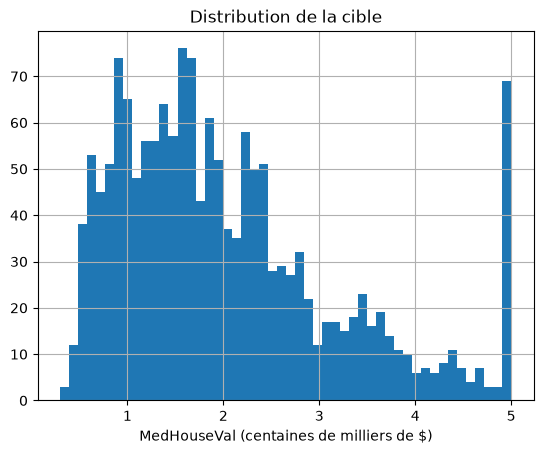

Part de valeurs plafonnées à 5.0 : 4.2%


In [4]:
# Distribution de la cible : palier visible à 5.0
import matplotlib.pyplot as plt

y_train.hist(bins=50)
plt.xlabel("MedHouseVal (centaines de milliers de $)")
plt.title("Distribution de la cible")
plt.show()
print(f"Part de valeurs plafonnées à 5.0 : {(y_train >= 5.0).mean():.1%}")

In [5]:
# Valeurs extrêmes : médiane, 99e percentile et maximum
X_train[["AveRooms", "AveBedrms", "AveOccup"]].quantile([0.5, 0.99, 1.0])

,AveRooms,AveBedrms,AveOccup
0.50,5.150964,1.046419,2.815166
0.99,10.861355,2.127214,5.279746
1.00,36.075472,7.968750,83.171429


In [6]:
# Entraînement XGBoost + petit tuning par validation croisée
import time
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

param_grid = {
    "n_estimators": [200, 500],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1],
}
search = GridSearchCV(
    XGBRegressor(random_state=42),
    param_grid, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
search.fit(X_train, y_train)
print("Meilleurs paramètres :", search.best_params_)
print(f"RMSE CV : {-search.best_score_:.3f}")

# Réentraînement du meilleur modèle seul, pour mesurer un temps de fit comparable à TabPFN
model = XGBRegressor(random_state=42, **search.best_params_)
t0 = time.perf_counter()
model.fit(X_train, y_train)
fit_time = time.perf_counter() - t0
print(f"Temps de fit : {fit_time:.3f} s")

Meilleurs paramètres : {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 500}
RMSE CV : 0.567
Temps de fit : 0.169 s


In [7]:
# Métriques sur le jeu de test
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

t0 = time.perf_counter()
y_pred = model.predict(X_test)
predict_time = time.perf_counter() - t0

metrics_xgb = {
    "rmse": float(np.sqrt(mean_squared_error(y_test, y_pred))),
    "mae": float(mean_absolute_error(y_test, y_pred)),
    "r2": float(r2_score(y_test, y_pred)),
    "fit_time": fit_time,
    "predict_time": predict_time,
}
metrics_xgb

{'rmse': 0.5422254865474705,
 'mae': 0.37096634490364794,
 'r2': 0.7874223697148506,
 'fit_time': 0.16941833300006692,
 'predict_time': 0.002453916000376921}

In [8]:
# SHAP : TreeExplainer avec le background partagé
import shap

explainer = shap.TreeExplainer(model, X_background)
shap_values = explainer(X_shap)

# Vérification de l'additivité : base value + somme des SHAP = prédiction
recon = shap_values.base_values + shap_values.values.sum(axis=1)
print("Additivité OK :", np.allclose(recon, model.predict(X_shap), atol=1e-4))

Additivité OK : True


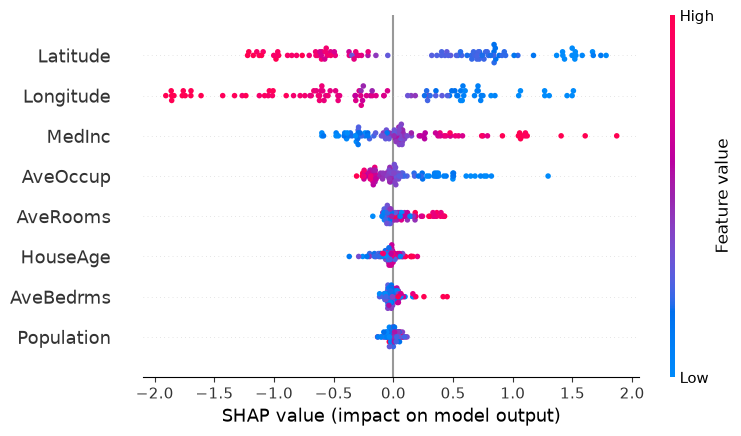

In [9]:
# Beeswarm : importance et effet de chaque variable sur les 100 points
shap.plots.beeswarm(shap_values)

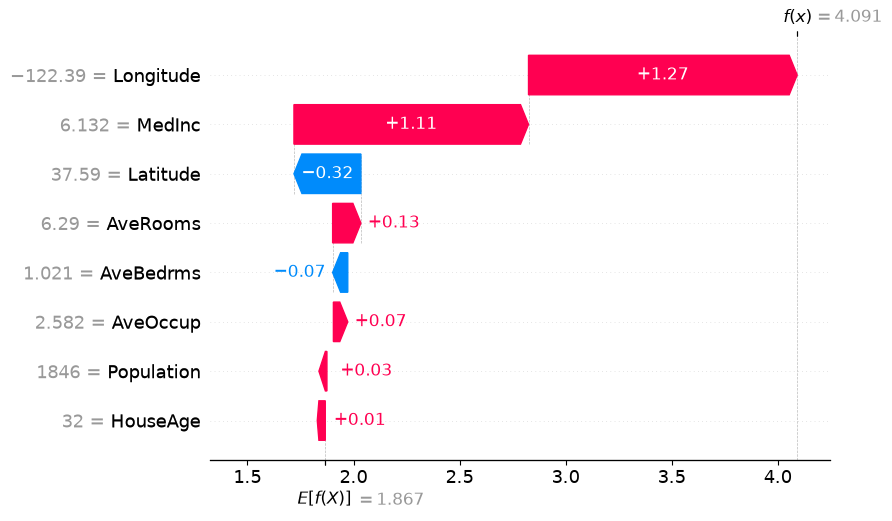

In [10]:
# Waterfall : détail d'une prédiction (point 0)
shap.plots.waterfall(shap_values[0])